# Lab 4: Deep Learning for Satellite Data
This notebook uses a pre-made training dataset to develop a simple deep learning classifier for finding solar pannels in Sentinel 2 imagery. The learning objectives for this lab are to:

1. Load and use a pre-labeled training dataset (e.g. polygons or patches with land cover classes).
2. Prepare that data for use in a deep learning model.
3. Train a deep learning model in TensorFlow/Keras using these labels.

At the end of the lab you will be asked to reflect on model performance, generalization, and sources of error.


In [1]:
# Set up, couple of new libraries here so expect install times to take longer than you have been used to
# ｜ 环境准备：几个新库，安装会比之前久
!pip install -q tensorflow rasterio geemap matplotlib scikit-learn scikit-image tqdm --quiet

import os                                            # 路径与文件操作
import zipfile                                       # 解压 train.zip
from pathlib import Path                             # 面向对象的路径工具
import numpy as np                                   # 数值计算
import re                                            # 正则：从文件名里抠编号
import rasterio                                      # 读 GeoTIFF
import cv2                                           # 图像缩放（resize_or_pad 用）
import glob                                          # 通配符找文件
import matplotlib.pyplot as plt                      # 画图
import tensorflow as tf                              # 深度学习框架
from tensorflow.keras import layers, models          # 建网络的积木
from tensorflow.keras.callbacks import EarlyStopping # 早停回调（防过拟合浪费时间）
from tqdm import tqdm                                # 进度条
from sklearn.model_selection import train_test_split # 划分数据集（本 lab 备用）
os.makedirs('lab4_figs', exist_ok=True)              # 报告用图目录（后面所有 savefig 都放这）

In [2]:
# Set our random seeds for reproducibility ｜ 固定随机种子保证可复现
SEED = 42 #<- the meaning of life, this is why you always see people setting seeds to 42 by the way... ｜ 42=生命、宇宙及一切的答案
np.random.seed(SEED)                                 # 固定 numpy 的随机序列
tf.random.set_seed(SEED)                             # 固定 TensorFlow 的随机序列

Your training data has been downloaded from:

*   [Solafune](https://solafune.com/competitions/5dfc315c-1b24-4573-804f-7de8d707cd90?id=&menu=data&topicId=54728653-0e25-4975-baad-6fe2f5185844)

Find the data on Canvas or download directly from their website the 'train.zip'. The competition that this dataset was created for is now over, but that is good for us as it means you can look at the winning solutions for inspiration!

If you want to download the data yourself you will need to sign up for an account and then 'enter' the competition. You can do this all without charge but it does require an email address sign up.

We are just going to use the 'train.zip' data and split that into our train and test, in order to reduce the burden on our notebooks. Remember that ultimately we would want to validate it, and you will see that the linked data source actually has a completely seperate store of images for that purpose.

Take that .zip file and get it into your g-drive/local space as per usual practice. Leave it zipped.


In [3]:
# Assume train.zip is already uploaded to Colab file store, extract it
# ｜ 本机改动：train.zip 已从 Canvas 下到 lab4_data/（Colab 原路径 /content/ 注释保留）
zip_path = "lab4_data/train.zip"                     # 压缩包位置（Colab 原为 /content/train.zip）
extract_dir = Path("lab4_data/train_data")           # 解压目的地（Colab 原为 /content/train_data）
extract_dir.mkdir(parents=True, exist_ok=True)       # 建目录，存在则跳过


with zipfile.ZipFile(zip_path, 'r') as z:            # 打开压缩包
  z.extractall(extract_dir)                          # 全部解压

With our data extracted, we now need to build lists of each sample patch and the labelled mask of it, connecting the two. I have written this relatively robustly (e.g. you can set it to handle different file extensions and it checks that it is finding the correct files), so that hopefully you can use it more widely than just in this lab.

In [4]:
# Set the file extenion we are using ｜ 要找的文件扩展名
f_ex = "*.tif"                                       # GeoTIFF

# Locate directories ｜ 自动定位两个子目录（不写死路径，解压结构变了也能找到）
s2_dir = next((p for p in extract_dir.rglob('*') if p.is_dir() and 's2_image' in p.name.lower()), None)      # 影像目录
mask_dir = next((p for p in extract_dir.rglob('*') if p.is_dir() and 'mask' in p.name.lower()), None)        # 掩膜目录

assert s2_dir and mask_dir, "Could not locate s2_image/ and mask/ directories."  # 找不到就报错
print("Found Sentinel-2 image dir:", s2_dir)         # 打印影像目录
print("Found mask dir:", mask_dir)                   # 打印掩膜目录

# Match files to each other from each sub-directory by trailing numeric ID
# ｜ 用文件名末尾的数字编号把影像和掩膜配对
s2_files = {re.search(r'_(\d+)\.tif$', f.name).group(1): f for f in Path(s2_dir).glob(f_ex)}    # 编号→影像路径
mask_files = {re.search(r'_(\d+)\.tif$', f.name).group(1): f for f in Path(mask_dir).glob(f_ex)}# 编号→掩膜路径

# Build pairs of images and masks ｜ 组装配对列表
common_ids = sorted(set(s2_files.keys()) & set(mask_files.keys()))   # 两边都有的编号
assert len(common_ids) > 0, "No paired s2_image/mask files found with matching IDs."             # 没配上就报错

pairs = []                                           # 收集配对
for i in common_ids:                                 # 逐编号
    s2_path, mask_path = s2_files[i], mask_files[i]  # 取出两个路径
    with rasterio.open(s2_path) as s2, rasterio.open(mask_path) as m:            # 同时打开检查
        assert (s2.height, s2.width) == (m.height, m.width), \
            f"Shape mismatch: {s2_path.name} vs {mask_path.name}"                # 尺寸必须一致
    pairs.append((s2_path, mask_path))               # 收进列表

print(f"Found {len(pairs)} valid paired samples.")   # 配对总数
print("Example pair:", pairs[0])                     # 示例

Found Sentinel-2 image dir: lab4_data\train_data\s2_image
Found mask dir: lab4_data\train_data\mask


C:\Users\fwang\AppData\Local\Programs\Python\Python311\Lib\site-packages\rasterio\__init__.py:368: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)


Found 2066 valid paired samples.
Example pair: (WindowsPath('lab4_data/train_data/s2_image/train_s2_image_0.tif'), WindowsPath('lab4_data/train_data/mask/train_mask_0.tif'))


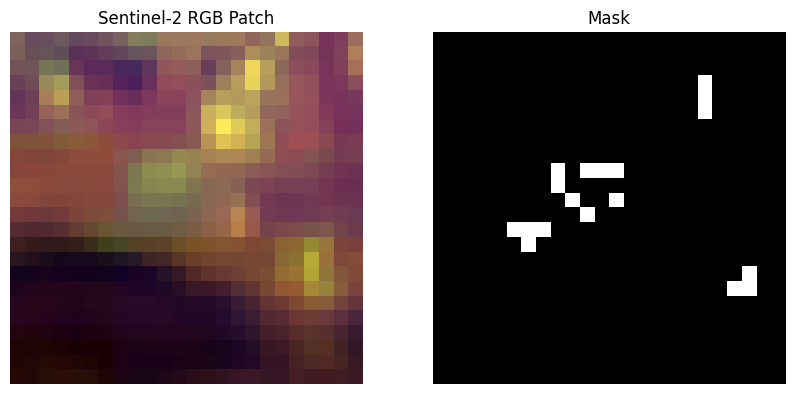

In [5]:
# Quick sanity check: visualize one random pair out of the first 31 available
# Run this cell a few times to check that you have different files and that the mask looks about right
# ｜ 抽查可视化（⚠️ 实测波段顺序是 B1,B2,B3,B4,...,B8A,B9,B11,B12——read([3,2,1]) 取到的
# ｜ 其实是 B3,B2,B1=绿/蓝/海岸气溶胶，不是注释声称的 B4,B3,B2 真彩，但显示效果差别不大）
pair_num = np.random.randint(0,30)                   # 随机挑一对
s2_path, mask_path = pairs[pair_num]                 # 取路径

with rasterio.open(s2_path) as src:                  # 打开影像
    s2_img = src.read([3,2,1])  # RGB bands for Sentinel-2 (B4, B3, B2) ｜ 实际=B3,B2,B1（见上）
    s2_img = np.transpose(s2_img, (1,2,0))           # (波段,高,宽) → (高,宽,波段)
    s2_img = (s2_img - s2_img.min()) / (s2_img.max() - s2_img.min())             # 拉伸到 0-1 便于显示

with rasterio.open(mask_path) as src:                # 打开掩膜
    mask = src.read(1)                               # 读第 1 波段

plt.figure(figsize=(10,5))                           # 建图
plt.subplot(1,2,1)                                   # 左图
plt.imshow(s2_img)                                   # 显示影像
plt.title("Sentinel-2 RGB Patch")                    # 标题
plt.axis("off")                                      # 关轴

plt.subplot(1,2,2)                                   # 右图
plt.imshow(mask, cmap="gray")                        # 显示掩膜
plt.title("Mask")                                    # 标题
plt.axis("off")                                      # 关轴
plt.show()                                           # 显示

Next up we are going to prepare our training data into numpy arrays that are then able to be passed into TensorFlow. However, if we try to hold all 2000+ patches in RAM whilst we do, the Colab instance will crash. If on your own laptop, it will also die unless you have spent a lot more money than I have on mine. Furthermore, even if we had a HPC level of RAM available it is a good idea to do things in a 'memory safe' manner that means we can scale our training with more samples if we so deisred it.

The safe pattern is therefore to:
1. Load a batch of patches.
2. Normalize/resize them.
3. Save them to disk (e.g. as .npy, .npz, or TFRecords/HDF5).
4. Free memory and move on.
5. Then later, when training, you stream batches directly from disk.

Here’s a disk-based pipeline with batching using numpy.savez_compressed (safe + easy to reload):

In [6]:
def resize_or_pad(arr, target_h, target_w):          # 把任意尺寸的阵列缩放到目标尺寸
    h, w = arr.shape[:2]                             # 原始高宽
    c = arr.shape[2] if arr.ndim == 3 else 1         # 通道数（掩膜是单通道）

    arr = cv2.resize(                                # 用 OpenCV 缩放
        arr,                                         # 输入阵列
        (target_w, target_h),                        # 目标 (宽,高)
        interpolation=cv2.INTER_NEAREST if c == 1 else cv2.INTER_LINEAR)         # 掩膜用最近邻（保 0/1），影像用双线性

    if arr.ndim == 2:                                # 单通道被压成 2 维时
        arr = arr[..., np.newaxis]                   # 补回通道维
    return arr                                       # 返回


# Set storage folder ｜ 批文件输出目录
OUTPUT_DIR = "patch_store"                           # npz 批文件放这里
os.makedirs(OUTPUT_DIR, exist_ok=True)               # 建目录

TARGET_HEIGHT, TARGET_WIDTH = 256, 256 # Tune based on memory available ｜ 存储尺寸（原始 patch 只有约 23×23，这里是大幅上采样）
BATCH_SIZE = 100  # Tune based on memory available ｜ 每个 npz 装 100 个样本


X_batch, Y_batch = [], []                            # 当前批的缓冲
batch_idx = 0                                        # 批序号

for i, (s2_path, mask_path) in enumerate(tqdm(pairs, desc="Processing")):        # 逐对处理（带进度条）
    # Load Sentinel-2 ｜ 读影像
    with rasterio.open(s2_path) as src:              # 打开
        img = src.read().astype(np.float32)  # (bands, H, W) ｜ 全部 12 个波段
        img = np.transpose(img, (1, 2, 0))  # (H, W, bands) ｜ 转成通道在后

    # Load mask ｜ 读掩膜
    with rasterio.open(mask_path) as src:            # 打开
        mask = src.read(1).astype(np.uint8)          # 单波段 0/1

    # Resize/pad ｜ 统一尺寸
    img = resize_or_pad(img, TARGET_HEIGHT, TARGET_WIDTH)        # 影像 → 256×256
    mask = resize_or_pad(mask, TARGET_HEIGHT, TARGET_WIDTH)      # 掩膜 → 256×256

    # Normalize ｜ 归一化（S2 反射率放大了 1 万倍）
    img = img / 10000.0                              # 除回反射率量级

    # Add to batch ｜ 加进当前批
    X_batch.append(img)                              # 影像
    Y_batch.append(mask)                             # 掩膜

    # Save batch to disk when full ｜ 攒够一批就落盘
    if len(X_batch) >= BATCH_SIZE:                   # 满 100 个
        X_batch = np.stack(X_batch)                  # 堆成 (100,256,256,12)
        Y_batch = np.stack(Y_batch)                  # 堆成 (100,256,256,1)

        np.savez_compressed(                         # 压缩保存
            os.path.join(OUTPUT_DIR, f"batch_{batch_idx:04d}.npz"),              # 文件名带批号
            X=X_batch, Y=Y_batch                     # 两个数组
        )

        # Reset ｜ 清空缓冲
        batch_idx += 1                               # 批号 +1
        X_batch, Y_batch = [], []                    # 重新开始攒

# Save any leftovers ｜ 不满一批的尾巴也要存
if len(X_batch) > 0:                                 # 有剩余
    X_batch = np.stack(X_batch)                      # 堆叠
    Y_batch = np.stack(Y_batch)                      # 堆叠
    np.savez_compressed(                             # 保存
        os.path.join(OUTPUT_DIR, f"batch_{batch_idx:04d}.npz"),  # 最后一批
        X=X_batch, Y=Y_batch                         # 两个数组
    )

# By the way it is the 'tqdm' element that is providing the nifty progress bar. I always like to include it when waiting for things so that I know it is actually running.
# ｜ 进度条就是 tqdm 提供的
# This block might take five to ten minutes to run as we are doing this in a linear manner (rather than parallell processing).
# An optimised version of thise code is to pass each batch to a seperate CPU thread/core.
# ｜ 串行处理要 5-10 分钟；优化版可以把每批扔给单独的 CPU 线程

Processing:   0%|          | 0/2066 [00:00<?, ?it/s]

Processing:   0%|          | 3/2066 [00:00<01:14, 27.61it/s]

Processing:   0%|          | 8/2066 [00:00<00:56, 36.69it/s]

Processing:   1%|          | 13/2066 [00:00<00:50, 40.75it/s]

Processing:   1%|          | 18/2066 [00:00<00:48, 42.60it/s]

...

Processing:  99%|█████████▉| 2055/2066 [10:03<00:00, 15.30it/s]

Processing: 100%|█████████▉| 2059/2066 [10:03<00:00, 19.66it/s]

Processing: 100%|█████████▉| 2062/2066 [10:03<00:00, 19.54it/s]

Processing: 100%|█████████▉| 2065/2066 [10:03<00:00, 15.58it/s]

Processing: 100%|██████████| 2066/2066 [10:03<00:00,  3.42it/s]

5-10 minutes later... (mine took 8 minutes and 32 seconds), we can now move on. Because we are now not storing our training data in our RAM like we did in the lecture exercise, we have to load it in as we want it.

First up, set a bunch of parameters that we can modify in order to save our RAM load. In short, the lower these values the less RAM you will use but the worse the results:

In [7]:
# Paramaters for RAM saving ｜ 省内存参数
TARGET_HEIGHT, TARGET_WIDTH = 128, 128  # smaller patch -> saves RAM & compute ｜ 训练时再缩到 128×128
BANDS = 3  # RGB only -> reduces memory ｜ 只取前 3 个通道（⚠️ 按实测波段序其实是 B1,B2,B3）
BATCH_SIZE = 4  # small batch -> reduces RAM usage ｜ 小批量
MAX_TRAIN_FILES = 5  # only use subset for lab demonstration ｜ 只用 5 个批文件当训练集（演示用）
MAX_VAL_FILES = 2                                    # 2 个批文件当验证集

**Q1**: We have used three bands here. What is the total numnber of bands we could make available to the CNN if we so chose?

In [8]:
# ---- Q1 证据：直接从数据里数波段 ----
with rasterio.open(pairs[0][0]) as src:              # 打开第一对的影像
    print('band count =', src.count)                 # 波段数
    print('patch size =', src.height, 'x', src.width)            # 原始 patch 尺寸（注意只有 ~23×23！）

band count = 12
patch size = 24 x 23


__ANSWER1_PLACEHOLDER__

Next we find our patch files:

In [9]:
# Locate the batched .npz files ｜ 找到全部批文件
all_files = sorted(glob.glob("patch_store/batch_*.npz"))         # 只匹配模板生成的批（避免混入后面 Q6 的新批）
np.random.shuffle(all_files)                         # 打乱文件顺序（种子已固定，可复现）

train_files = all_files[:MAX_TRAIN_FILES]            # 前 5 个当训练
val_files   = all_files[-MAX_VAL_FILES:]             # 最后 2 个当验证
print(f'{len(all_files)} batch files total; train={len(train_files)}, val={len(val_files)}')     # 打印划分

21 batch files total; train=5, val=2


**Q2**: What is the total number of patches in our training data and the total number in our validation set? (With the parameters set as I have done in the notebook).

Tip: you can either programmatically count what is in train_files/val_files, or you can calculate it from the parameters that have been set across the cells above this one.

In [10]:
# ---- Q2 证据：数一数两个子集里到底有多少个 patch，顺带看正样本率 ----
def batch_stats(files):                              # 统计一组批文件
    n, pos = 0, 0                                    # 总数与正样本数
    for f in files:                                  # 逐文件
        d = np.load(f)                               # 载入
        n += d['X'].shape[0]                         # 累计 patch 数
        pos += int((d['Y'].sum(axis=(1, 2, 3)) > 0).sum())       # 掩膜里有光伏像元的 patch 数
    return n, pos                                    # 返回

n_tr, p_tr = batch_stats(train_files)                # 训练集统计
n_va, p_va = batch_stats(val_files)                  # 验证集统计
print(f'train: {n_tr} patches, positive {p_tr} ({p_tr/n_tr:.1%})')               # 训练集：总数+正率
print(f'val  : {n_va} patches, positive {p_va} ({p_va/n_va:.1%})')               # 验证集：总数+正率

train: 500 patches, positive 467 (93.4%)
val  : 200 patches, positive 183 (91.5%)


__ANSWER2_PLACEHOLDER__

We then we need to change our masks to a binary label. If we were doing segmenation we would keep it as a mask, but in this case we are just trying to find patches that contain solar pannels rather than the specific solar pannel outline.

In [11]:
# Mask to binary label ｜ 把整幅掩膜压成一个二值标签
def mask_to_label(mask_batch):
    """1 if any solar pixel in mask, else 0"""
    labels = (np.sum(mask_batch, axis=(1,2,3)) > 0).astype(np.float32)           # 掩膜里只要有 1 个光伏像元 → 标签 1
    return labels                                    # 返回一批标签

Now we need a tool to load our data in from the batched files:

In [12]:
# Data loader ｜ 数据装载器：读一个 npz 批并做训练前处理
def npz_loader_cls(path):
    """Load one .npz batch, downsample patches, convert to RGB, convert mask to label"""
    data = np.load(path.numpy().decode("utf-8"))     # tf 传进来的是字节张量，解码成路径再载入
    X = data["X"]                                    # 影像批 (100,256,256,12)
    Y_mask = data["Y"]                               # 掩膜批 (100,256,256,1)

    # RAM saving: pick first 3 bands only ｜ 省内存：只取前 3 个通道
    X = X[..., :BANDS]                               # (100,256,256,3)

    # RAM saving: downsample patches ｜ 省内存：降采样到 128×128
    from skimage.transform import resize             # 用 skimage 的抗锯齿缩放
    X_resized = np.zeros((X.shape[0], TARGET_HEIGHT, TARGET_WIDTH, BANDS), dtype=np.float32)     # 预分配
    for i in range(X.shape[0]):                      # 逐样本
        X_resized[i] = resize(X[i], (TARGET_HEIGHT, TARGET_WIDTH, BANDS), anti_aliasing=True)    # 缩放

    X = X_resized                                    # 换成缩放后的

    Y = mask_to_label(Y_mask)                        # 掩膜 → 二值标签
    return X, Y                                      # 返回一批样本

We can now define our training and validation datasets, which will only be actually populated with data as required, rather than loading it all into memory at once.

In [13]:
# TensorFlow dataset pipeline ｜ tf.data 流水线：按需读文件，不一次性进内存
def tf_wrapper(path):
    X, Y = tf.py_function(npz_loader_cls, [path], [tf.float32, tf.float32])      # 把 python 装载器包成 tf 算子
    X.set_shape([None, TARGET_HEIGHT, TARGET_WIDTH, BANDS])      # 声明形状（py_function 会丢形状信息）
    Y.set_shape([None])                              # 标签形状
    # Flatten file-batch into individual samples ｜ 把文件级批拆成单个样本
    return tf.data.Dataset.from_tensor_slices((X, Y))            # 逐样本的数据集

def make_cls_dataset(file_list, batch_size=BATCH_SIZE, shuffle=True, repeat=True):
    files = tf.data.Dataset.from_tensor_slices(file_list)        # 文件名数据集
    if shuffle:                                      # 训练集要打乱
        files = files.shuffle(len(file_list))        # 文件顺序打乱

    # RAM saving: stream samples via interleave ｜ 用 interleave 流式交错读取多个文件
    ds = files.interleave(
        lambda f: tf_wrapper(f),                     # 每个文件展开成样本流
        cycle_length=4,                              # 同时打开 4 个文件交错
        num_parallel_calls=tf.data.AUTOTUNE)         # 并行度自动调

    if shuffle:                                      # 训练集再做样本级打乱
        ds = ds.shuffle(2048)                        # 2048 大小的洗牌缓冲

    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)         # 组小批 + 预取

    if repeat:                                       # 训练集无限循环（按步数训练）
        ds = ds.repeat()                             # 循环

    return ds                                        # 返回数据集

train_ds = make_cls_dataset(train_files, batch_size=BATCH_SIZE, shuffle=True)    # 训练集：打乱+循环
val_ds   = make_cls_dataset(val_files, batch_size=BATCH_SIZE, shuffle=False, repeat=False)       # 验证集：不打乱不循环

**Q3**: Are we shuffling the training dataset? Are we shuffling the validation dataset?

__ANSWER3_PLACEHOLDER__

Finally, we need to specify our model settings. We are just using a simple CNN here, the same sort as we used the lecture exercise. But, this time it has signficantly more layers and therefore parameters (but far less than you might use for your project). It may take a few minutes to set up:

In [14]:
# We are determining the input shape from one batch first ｜ 先取一批探出输入形状
for X_sample, _ in train_ds.take(1):                 # 取一批
    input_shape = X_sample.shape[1:]  # (H, W, bands) ｜ 去掉批维
    break                                            # 只要一批

# Define a simple CNN ｜ 定义一个极简 CNN
inputs = layers.Input(shape=input_shape)             # 输入层
x = layers.Conv2D(16, 3, activation='relu', padding='same')(inputs)              # 卷积 16 个 3×3 滤波器
x = layers.MaxPooling2D((2,2))(x)                    # 2×2 最大池化（尺寸减半）
x = layers.Conv2D(32, 3, activation='relu', padding='same')(x)   # 卷积 32 个滤波器
x = layers.GlobalAveragePooling2D()(x)               # 全局平均池化（任意尺寸 → 32 维向量）
x = layers.Dense(32, activation='relu')(x)           # 全连接 32
outputs = layers.Dense(1, activation='sigmoid')(x)   # 输出层：1 个神经元 + sigmoid → 概率

model = models.Model(inputs, outputs)                # 组装模型
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])# 二元交叉熵 + Adam
model.summary()                                      # 打印结构

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,177 (24.13 KB)

 Trainable params: 6,177 (24.13 KB)

 Non-trainable params: 0 (0.00 B)

**Q4**: Which type of activation funding is our final layer using and why are we using this function as our final layer?

__ANSWER4_PLACEHOLDER__

With the model ready to train, we have one more preperation step to make. We need to count the total samples available in this particular run. This is because you can change the number of samples via the RAM paramaters earlier, and therefore we should assume in this code a static number of samples will always be available when setting our number of steps per epoch.

In [15]:
# Count the total samples ｜ 数一数总样本量（算每轮要走多少步）
def count_samples(files):
    total = 0                                        # 计数器
    for f in files:                                  # 逐文件
        total += np.load(f)["X"].shape[0]            # 累加该批样本数
    return total                                     # 返回总数

n_train = count_samples(train_files)                 # 训练样本数
n_val   = count_samples(val_files)                   # 验证样本数
print(f'n_train={n_train}, n_val={n_val}')           # 打印（Q2 的官方数字）

steps_per_epoch = max(1, n_train // BATCH_SIZE)      # 每轮训练步数
validation_steps = max(1, n_val // BATCH_SIZE)       # 每轮验证步数

n_train=500, n_val=200


Finally, we train the model! It should take 5-10 minutes to run on a free-user Colab notebook.

In [16]:
# This 'callbacks' set of instructions is a handy way to avoid wasting time ｜ 回调：不浪费时间的小工具
callbacks = [
    EarlyStopping(
        monitor="val_loss",          # Watch the validation loss ｜ 盯验证损失
        patience=3,                  # If it doesn't improve for 3 epochs, stop training ｜ 3 轮不降就停
        restore_best_weights=True    # Roll back to the best-performing weights ｜ 回滚到最优权重
    )]

# Run the model ｜ 开训
history = model.fit(
    train_ds,                                        # 训练数据
    steps_per_epoch=steps_per_epoch,                 # 每轮步数
    validation_data=val_ds,                          # 验证数据
    validation_steps=validation_steps,               # 验证步数
    epochs=5,  # small number for lab demonstration ｜ 演示只跑 5 轮
    callbacks=callbacks)                             # 挂上早停

C:\Users\fwang\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/5


  1/125 ━━━━━━━━━━━━━━━━━━━━ 1:32:59 45s/step - accuracy: 1.0000 - loss: 0.6905

  2/125 ━━━━━━━━━━━━━━━━━━━━ 19s 156ms/step - accuracy: 1.0000 - loss: 0.6876  

  4/125 ━━━━━━━━━━━━━━━━━━━━ 8s 70ms/step - accuracy: 1.0000 - loss: 0.6819  

...

100/125 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9250 - loss: 0.2806

108/125 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9282 - loss: 0.2716

116/125 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9332 - loss: 0.2580

122/125 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9324 - loss: 0.2607

125/125 ━━━━━━━━━━━━━━━━━━━━ 19s 69ms/step - accuracy: 0.9340 - loss: 0.2556 - val_accuracy: 0.9150 - val_loss: 0.3109


Visualizie the predictions:

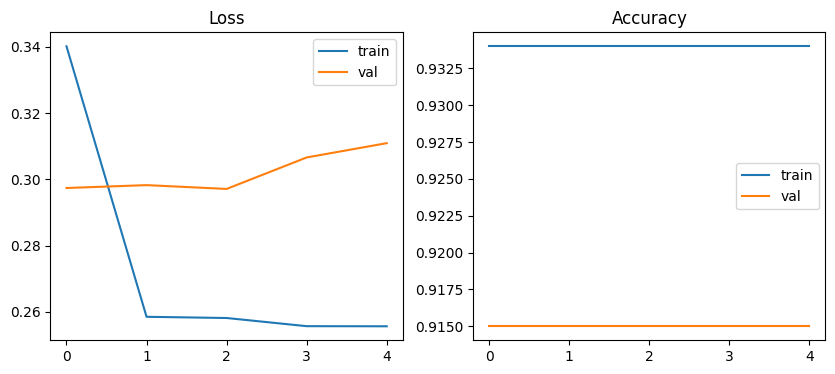

In [17]:
# Plot the training curves ｜ 画训练曲线
plt.figure(figsize=(10,4))                           # 建图
plt.subplot(1,2,1)                                   # 左：损失
plt.plot(history.history['loss'], label="train")     # 训练损失
plt.plot(history.history['val_loss'], label="val")   # 验证损失
plt.title("Loss")                                    # 标题
plt.legend()                                         # 图例

plt.subplot(1,2,2)                                   # 右：准确率
plt.plot(history.history['accuracy'], label="train") # 训练准确率
plt.plot(history.history['val_accuracy'], label="val")           # 验证准确率
plt.title("Accuracy")                                # 标题
plt.legend()                                         # 图例
plt.savefig('lab4_figs/fig_v1_curves.png', dpi=110, bbox_inches='tight')         # 存盘（Q5/Q7 证据）
plt.show()                                           # 显示

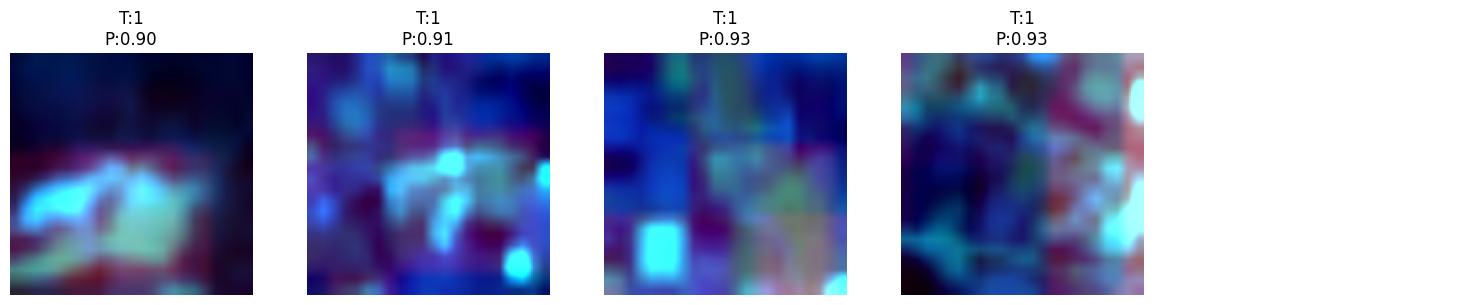

In [18]:
def show_patch_predictions_grid(dataset, model, n_rows=2, n_cols=5):
    """
    Display predictions in a grid: n_rows x n_cols
    Includes histogram stretch for better visualization of RGB patches.
    """                                              # 预测结果九宫格展示
    def stretch(img):
        """Contrast stretch to 0-1 for display."""
        img = img.astype(np.float32)                 # 转浮点
        p2, p98 = np.percentile(img, (2, 98))        # 2%/98% 分位
        img = np.clip((img - p2) / (p98 - p2 + 1e-6), 0, 1)      # 分位拉伸
        return img                                   # 返回

    for X, Y_true in dataset.take(1):                # 取一批
        # live classification of the patch using the trained model ｜ 现场推理
        Y_pred = model.predict(X, verbose=0)         # 模型输出概率
        n_total = min(n_rows * n_cols, X.shape[0])   # 展示数量

        fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols*3, n_rows*3))   # 网格画布
        axes = axes.flatten()                        # 摊平便于索引

        for i in range(n_total):                     # 逐格
            rgb = X[i, :, :, :3].numpy()             # 取前 3 通道当"RGB"
            rgb = stretch(rgb)  # apply histogram stretch ｜ 拉伸
            axes[i].imshow(rgb)                      # 显示
            axes[i].set_title(f"T:{int(Y_true[i].numpy())}\nP:{Y_pred[i,0]:.2f}")               # 真值 T / 预测 P
            axes[i].axis("off")                      # 关轴

        # hide any unused axes ｜ 多余格子藏起来
        for i in range(n_total, len(axes)):          # 剩余
            axes[i].axis("off")                      # 关轴

        plt.tight_layout()                           # 收紧
        plt.savefig('lab4_figs/fig_v1_preds.png', dpi=110, bbox_inches='tight')  # 存盘
        plt.show()                                   # 显示

# Example ｜ 示例：看验证集一批
show_patch_predictions_grid(val_ds, model, n_rows=1, n_cols=5)

**（自加）Q5 证据**：单看 accuracy 会被 90% 的正样本率骗——下面算出「无脑全答 1」的基线，再算模型真实的查准/查全。

In [19]:
# ---- Q5 证据：模型 vs「永远预测有光伏」的无脑基线 ----
ys, ps = [], []                                      # 收集真值与预测
for X, Y in val_ds:                                  # 遍历验证集
    ps.append(model.predict(X, verbose=0)[:, 0])     # 预测概率
    ys.append(Y.numpy())                             # 真值
ys = np.concatenate(ys); ps = np.concatenate(ps)     # 拼成向量
pred = (ps > 0.5).astype(int)                        # 0.5 阈值二值化
acc = (pred == ys).mean()                            # 准确率
tp = int(((pred == 1) & (ys == 1)).sum()); fp = int(((pred == 1) & (ys == 0)).sum())             # 真阳/假阳
fn = int(((pred == 0) & (ys == 1)).sum()); tn = int(((pred == 0) & (ys == 0)).sum())             # 假阴/真阴
prec = tp / max(1, tp + fp); rec = tp / max(1, tp + fn)          # 查准率/查全率
print(f'model    : acc={acc:.1%}  precision={prec:.1%}  recall={rec:.1%}  (tp={tp} fp={fp} fn={fn} tn={tn})')    # 模型成绩
print(f'always-1 : acc={ys.mean():.1%}  ← 无脑全答 1 的基线（=验证集正样本率）')   # 基线成绩

model    : acc=91.5%  precision=91.5%  recall=100.0%  (tp=183 fp=17 fn=0 tn=0)
always-1 : acc=91.5%  ← 无脑全答 1 的基线（=验证集正样本率）


Remembering that this is a effectively still a toy CNN with tiny data, we can see that we have built a model that gives us a probability of the patches containing a solar pannel. We know that for all of the patchs used in this training, the answer is true...

**Q5**: Is this a robust and reliable model for the detection of solar panels in a new Sentinel 2 image that has never been seen by the model before? Explain your answer with reference to the design of the training data, the settings of the CNN and the performance statistics seen.

__ANSWER5_PLACEHOLDER__

**Q6**: Exercise: using the materials taught in Lab 3 and given your answer to Q5, re-design your training data so that it is a robust training set for the detection of solar panels in S2 data. Your answer needs to include:
*   A paragraph that explains what you have added to the train_data and any other steps taken in order to enhance the robustness of the training.
*   A figure that demonstrates your newly added patches vs. the existing patches (remember that it needs to be publication quality).

You do not need to create a 100% solution here. I am looking for you to demonstrate an understanding of the critical design flaw in this training set (particularly for a patch based, as opposed to segmentation, approach), and to show critical thinking in how you might fix it. This may include re-sampling the existing training data, including new training data, or changing the bands being used (or all of the above).



**（自加）Q6 实现**：这套训练数据的致命伤是 **patch 级标签 + 90% 都是正样本 + 全部来自同一竞赛区域**——负样本只有 10% 且和正样本同景，模型可以靠「场景长得像竞赛区就答有」蒙到 90% 准确率，从没真正学过「什么不是光伏」。
用 Lab 3 的技能修：在奥克兰四种地表（市区/森林/海面/农田）上做 **s2cloudless 无云中值合成**（Lab 3 调优参数），按 **UTM 10m 原生分辨率**抓 200 个 24×24 的 **hard negative** patch（波段 B1,B2,B3,B4,B8，与现有数据的通道对齐），作为新的负样本批注入 patch_store。

In [20]:
# ---- Q6：用 Lab 3 的管线从 EE 抓多样化负样本 patch ----
import ee                                            # Earth Engine
EE_PROJECT = os.environ.get('EE_PROJECT', 'geog761-ai')          # 项目名：本机用环境变量覆盖
try:                                                 # 先试免弹窗初始化
    ee.Initialize(project=EE_PROJECT)                # 本机走 ADC
except Exception:                                    # Colab 首次
    ee.Authenticate()                                # 浏览器授权
    ee.Initialize(project=EE_PROJECT)                # 再初始化

AOI_AKL = ee.Geometry.Point(174.7633, -36.8485)      # 奥克兰
S_DATE, E_DATE = '2023-01-01', '2023-03-31'          # 与 Lab 3 相同的时间窗
P_TH, N_TH, D_KM, BUF = 40, 0.18, 2, 60              # Lab 3 Q2 调优出的掩膜参数

def s2_cloudfree_composite():                        # 紧凑版 Lab 3 管线：s2cloudless 掩膜 + 中值合成
    s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')      # SR 影像
          .filterBounds(AOI_AKL).filterDate(S_DATE, E_DATE)      # 时空过滤
          .filter(ee.Filter.lte('CLOUDY_PIXEL_PERCENTAGE', 60))) # 场景级过滤
    prb = (ee.ImageCollection('COPERNICUS/S2_CLOUD_PROBABILITY') # 云概率
           .filterBounds(AOI_AKL).filterDate(S_DATE, E_DATE))    # 同样过滤
    col = ee.ImageCollection(ee.Join.saveFirst('s2c').apply(**{  # 按影像编号配对
        'primary': s2, 'secondary': prb,
        'condition': ee.Filter.equals(**{'leftField': 'system:index', 'rightField': 'system:index'})}))
    def mask_one(img):                               # 单景加掩膜并抠云（Lab 3 逻辑的紧凑版）
        p = ee.Image(img.get('s2c')).select('probability')       # 云概率
        clouds = p.gt(P_TH).rename('clouds')         # 概率阈值判云
        nw = img.select('SCL').neq(6)                # 非水
        dark = img.select('B8').lt(N_TH * 1e4).multiply(nw)      # 暗像元
        az = ee.Number(90).subtract(ee.Number(img.get('MEAN_SOLAR_AZIMUTH_ANGLE')))              # 影子方向
        proj = (clouds.directionalDistanceTransform(az, D_KM * 10)               # 云投影
                .reproject(**{'crs': img.select(0).projection(), 'scale': 100})  # 100m 上算
                .select('distance').mask())          # 转掩膜
        shadows = proj.multiply(dark)                # 暗 ∩ 投影 = 影子
        m = clouds.add(shadows).gt(0)                # 云 ∪ 影
        m = (m.focalMin(2).focalMax(BUF * 2 / 20)    # 去斑 + 扩边
             .reproject(**{'crs': img.select([0]).projection(), 'scale': 20}))   # 20m 网格
        return img.updateMask(m.Not())               # 抠掉云影
    return col.map(mask_one).median()                # 中值合成 → 无云图

EE_BANDS = ['B1', 'B2', 'B3', 'B4', 'B8']            # 抓这 5 个波段：前 3 个与现有数据的前 3 通道(B1,B2,B3)对齐，B4/B8 给重设计用
comp = (s2_cloudfree_composite().select(EE_BANDS)    # 无云合成图选波段
        .reproject(crs='EPSG:32760', scale=10))      # ⚠️ 必须重投影到 UTM 10m——合成图默认投影是 1 度/像素，sampleRectangle 只会给回 1×1（踩过）

NEG_SITES = {                                        # 四种地表的采样中心（同 Lab 3 Q6）
    'urban':    (174.7633, -36.8485),                # 市区
    'forest':   (174.5250, -36.9350),                # 森林
    'water':    (174.9700, -36.7500),                # 海面
    'farmland': (174.9300, -37.0700),                # 农田
}
N_PER_SITE = 50                                      # 每种地表 50 个 → 共 200 个负样本

import random                                        # 撒随机点
from concurrent.futures import ThreadPoolExecutor    # 并行抓取（串行要 200 秒+）

def grab_patch(args):                                # 抓一个 24×24 patch
    lon, lat = args                                  # 中心经纬度
    reg = ee.Geometry.Point(lon, lat).buffer(115).bounds()       # ~230m 见方 ≈ 23-24 像素
    r = comp.sampleRectangle(region=reg, defaultValue=0).getInfo()               # 整块拉回本地
    p = r['properties']                              # 各波段的二维列表
    return np.stack([np.array(p[b], dtype=np.float32) for b in EE_BANDS], axis=-1)               # (H,W,5)

jobs, sites_of = [], []                              # 任务列表与站点标签
rng = random.Random(SEED)                            # 固定种子
for site, (clon, clat) in NEG_SITES.items():         # 逐站点
    for _ in range(N_PER_SITE):                      # 每站点 50 个
        jobs.append((clon + rng.uniform(-0.02, 0.02), clat + rng.uniform(-0.02, 0.02)))          # 中心 ±2km 内撒点
        sites_of.append(site)                        # 记站点

with ThreadPoolExecutor(8) as ex:                    # 8 线程并行
    neg_patches = list(tqdm(ex.map(grab_patch, jobs), total=len(jobs), desc='EE patches'))       # 抓全部 patch

neg_X = np.stack([resize_or_pad(a, 256, 256) / 10000.0 for a in neg_patches]).astype(np.float32) # 统一到 256×256 并归一化（与 patch_store 约定一致）
neg_Y = np.zeros((len(neg_patches), 256, 256, 1), dtype=np.uint8)                # 负样本掩膜=全 0
for k in range(0, len(neg_patches), 50):             # 每 50 个存一个批文件
    np.savez_compressed(f'patch_store/neg_batch_{k//50:04d}.npz',                # 命名区别于模板批
                        X=neg_X[k:k+50], Y=neg_Y[k:k+50],        # 数据
                        sites=np.array(sites_of[k:k+50]))        # 站点标签（画图用）
print(f'saved {len(neg_patches)} negative patches from {len(NEG_SITES)} landcover sites')        # 汇报

EE patches:   0%|          | 0/200 [00:00<?, ?it/s]

EE patches:   0%|          | 1/200 [00:29<1:36:14, 29.02s/it]

EE patches:   4%|▍         | 8/200 [00:32<10:02,  3.14s/it]  

EE patches:   8%|▊         | 15/200 [00:33<04:24,  1.43s/it]

EE patches:  17%|█▋        | 34/200 [00:34<01:17,  2.15it/s]

...

EE patches:  97%|█████████▋| 194/200 [01:47<00:01,  3.15it/s]

EE patches:  98%|█████████▊| 196/200 [01:48<00:01,  2.91it/s]

EE patches: 100%|██████████| 200/200 [01:48<00:00,  3.58it/s]

EE patches: 100%|██████████| 200/200 [01:48<00:00,  1.84it/s]

saved 200 negative patches from 4 landcover sites


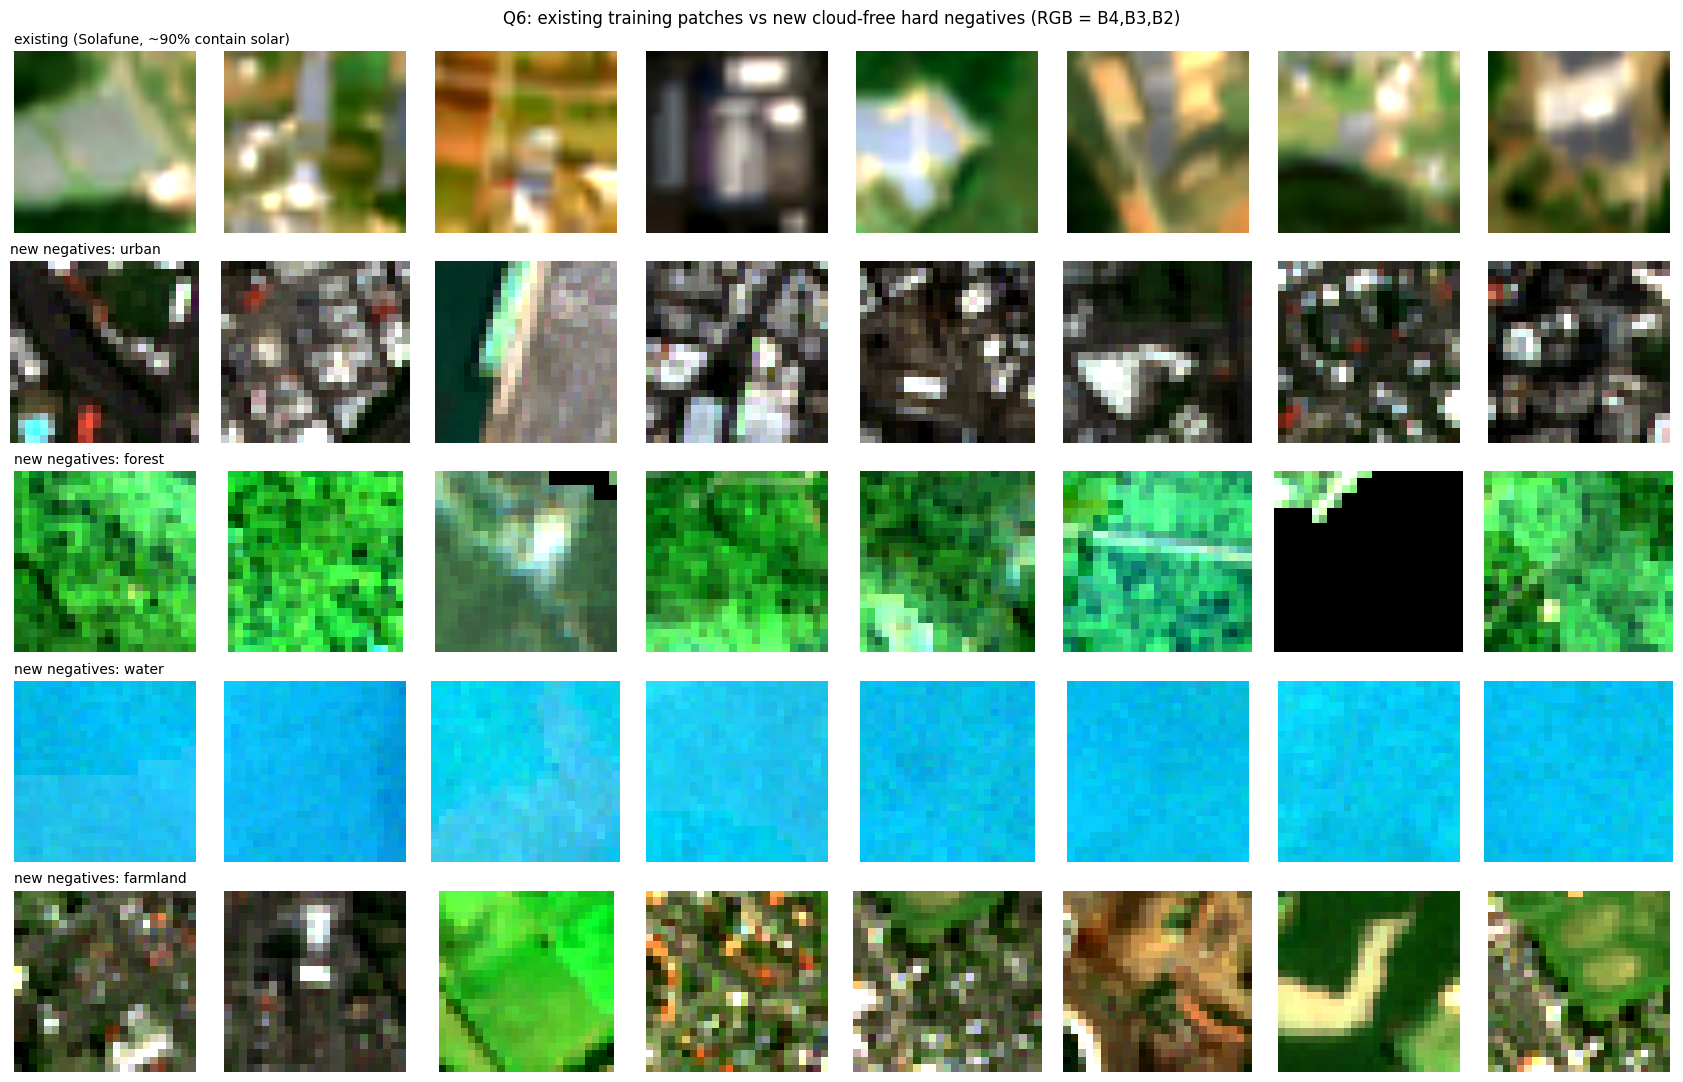

In [21]:
# ---- Q6 成果图：新负样本 vs 现有 patch ----
def stretch01(img):                                  # 2-98 分位拉伸便于显示
    p2, p98 = np.percentile(img, (2, 98))            # 分位
    return np.clip((img - p2) / (p98 - p2 + 1e-6), 0, 1)         # 拉伸

old = np.load(train_files[0])['X']                   # 现有的一批
fig, axes = plt.subplots(5, 8, figsize=(17, 11))     # 5 行 8 列：1 行现有 + 4 行新负样本
for j in range(8):                                   # 第 1 行：现有 patch（真彩=12 波段里的 B4,B3,B2 → 索引 3,2,1）
    axes[0][j].imshow(stretch01(old[j][:, :, [3, 2, 1]])); axes[0][j].axis('off')                # 显示
site_names = list(NEG_SITES.keys())                  # 四个站点名
for i, site in enumerate(site_names):                # 行 2-5 = urban/forest/water/farmland 各 8 个
    idx = [k for k, s in enumerate(sites_of) if s == site][:8]   # 该站点前 8 个
    for j, k in enumerate(idx):                      # 逐格
        axes[i + 1][j].imshow(stretch01(neg_patches[k][:, :, [3, 2, 1]])); axes[i + 1][j].axis('off')            # 真彩=B4,B3,B2（5 波段里索引 3,2,1）
row_labels = ['existing (Solafune, ~90% contain solar)'] + [f'new negatives: {s}' for s in site_names]           # 行标题文本
for ax, lab in zip(axes[:, 0], row_labels):          # 逐行
    ax.set_title(lab, fontsize=10, loc='left')       # 标在行首格上方
plt.suptitle('Q6: existing training patches vs new cloud-free hard negatives (RGB = B4,B3,B2)')   # 总标题
plt.tight_layout()                                   # 收紧
plt.savefig('lab4_figs/fig_q6_patches.png', dpi=110, bbox_inches='tight')        # 存盘（Q6 成果图）
plt.show()                                           # 显示

__ANSWER6_PLACEHOLDER__

**Q7**: Exercise: re-run the model with your new training data (remembering that I am not looking for a total solution), and further adjusted hyperparameters/RAM options. Write two paragraphs that:
1. Sets out **all the changes** you have made and the reasoning for them.
2. Asses the training and model results in terms of performance statistics, commenting on how/if your training data changes have made an impact.

You may include figures to support your analysis if you wish, remembering to present them to publication standard if you do so.

**（自加）Q7 实现**：重设计后的完整重训。改动清单：
1. **通道**：显式选 B2,B3,B4,B8（旧数据取 12 波段的索引 1,2,3,7；新负样本取 5 波段的索引 1,2,3,4）——不再用「前 3 个通道」那种实际是 B1,B2,B3 的糊涂账，且把对光伏最有区分力的近红外 B8 加进来
2. **尺寸**：128→**32×32**——原始 patch 只有 ~23×23，放大到 128 全是插值脑补
3. **数据量**：5+2 个批文件 → **全部 21 个批 + 4 个新负样本批**，按文件做分层划分
4. **类不平衡**：class_weight 按正负比例加权，同时汇报查准/查全而不是只看 accuracy

In [22]:
# ---- Q7：重设计后的数据管线与训练 ----
TARGET_V2 = 32                                       # 训练尺寸：贴近原生 ~23×23，只轻微上采样
CH_OLD = [1, 2, 3, 7]                                # 旧 12 波段里的 B2,B3,B4,B8
CH_NEW = [1, 2, 3, 4]                                # 新 5 波段里的 B2,B3,B4,B8

old_files = sorted(glob.glob('patch_store/batch_*.npz'))         # 全部旧批
neg_files = sorted(glob.glob('patch_store/neg_batch_*.npz'))     # 全部新负样本批
rng2 = np.random.RandomState(SEED)                   # 独立随机源
rng2.shuffle(old_files)                              # 打乱旧批
train_v2 = old_files[:-4] + neg_files[:-1]           # 训练：17 个旧批 + 3 个负样本批
val_v2   = old_files[-4:] + neg_files[-1:]           # 验证：4 个旧批 + 1 个负样本批（两种来源都在）
print(f'train files={len(train_v2)}, val files={len(val_v2)}')   # 打印划分

def npz_loader_v2(path):                             # v2 装载器：显式通道 + 32×32
    data = np.load(path.numpy().decode('utf-8'))     # 载入
    X = data['X']                                    # 影像批
    ch = CH_OLD if X.shape[-1] == 12 else CH_NEW     # 按波段数选通道索引
    X = X[..., ch]                                   # 取 B2,B3,B4,B8
    from skimage.transform import resize             # 缩放
    Xr = np.zeros((X.shape[0], TARGET_V2, TARGET_V2, 4), dtype=np.float32)       # 预分配
    for i in range(X.shape[0]):                      # 逐样本
        Xr[i] = resize(X[i], (TARGET_V2, TARGET_V2, 4), anti_aliasing=True)      # 缩到 32×32
    Y = mask_to_label(data['Y'])                     # 掩膜 → 标签
    return Xr, Y                                     # 返回

def tf_wrapper_v2(path):                             # tf 包装
    X, Y = tf.py_function(npz_loader_v2, [path], [tf.float32, tf.float32])       # 包成算子
    X.set_shape([None, TARGET_V2, TARGET_V2, 4])     # 形状声明
    Y.set_shape([None])                              # 标签形状
    return tf.data.Dataset.from_tensor_slices((X, Y))            # 拆成样本

def make_ds_v2(files, shuffle, repeat):              # 组数据集
    ds = tf.data.Dataset.from_tensor_slices(files)   # 文件名
    if shuffle: ds = ds.shuffle(len(files))          # 文件级打乱
    ds = ds.interleave(tf_wrapper_v2, cycle_length=4, num_parallel_calls=tf.data.AUTOTUNE)       # 交错流式
    if shuffle: ds = ds.shuffle(2048)                # 样本级打乱
    ds = ds.batch(32).prefetch(tf.data.AUTOTUNE)     # 批量 32（样本小了批可以放大）
    if repeat: ds = ds.repeat()                      # 训练集循环
    return ds                                        # 返回

train_ds2 = make_ds_v2(train_v2, True, True)         # 训练集
val_ds2   = make_ds_v2(val_v2, False, False)         # 验证集

n_tr2, p_tr2 = batch_stats(train_v2)                 # 训练统计（复用 Q2 的函数）
n_va2, p_va2 = batch_stats(val_v2)                   # 验证统计
print(f'train v2: {n_tr2} patches ({p_tr2/n_tr2:.1%} positive)')                 # 打印
print(f'val   v2: {n_va2} patches ({p_va2/n_va2:.1%} positive)')                 # 打印
w1 = n_tr2 / (2 * p_tr2); w0 = n_tr2 / (2 * (n_tr2 - p_tr2))     # 类权重：按频率反比
print(f'class_weight: 0 -> {w0:.2f}, 1 -> {w1:.2f}') # 打印权重

train files=20, val files=5


train v2: 1816 patches (85.7% positive)
val   v2: 450 patches (80.7% positive)
class_weight: 0 -> 3.51, 1 -> 0.58


In [23]:
# ---- Q7：v2 模型训练 ----
inputs2 = layers.Input(shape=(TARGET_V2, TARGET_V2, 4))          # 输入 32×32×4
x = layers.Conv2D(16, 3, activation='relu', padding='same')(inputs2)             # 卷积 16
x = layers.MaxPooling2D((2, 2))(x)                   # 池化
x = layers.Conv2D(32, 3, activation='relu', padding='same')(x)   # 卷积 32
x = layers.GlobalAveragePooling2D()(x)               # 全局平均池化
x = layers.Dense(32, activation='relu')(x)           # 全连接
outputs2 = layers.Dense(1, activation='sigmoid')(x)  # sigmoid 概率输出

model2 = models.Model(inputs2, outputs2)             # 组装（结构与 v1 相同，变量只在数据）
model2.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])               # 同样编译
steps2 = max(1, n_tr2 // 32)                         # 每轮步数
vsteps2 = max(1, n_va2 // 32)                        # 验证步数
history2 = model2.fit(                               # 开训
    train_ds2, steps_per_epoch=steps2,               # 训练数据与步数
    validation_data=val_ds2, validation_steps=vsteps2,           # 验证数据与步数
    epochs=15,                                       # 数据多了，轮数放宽
    class_weight={0: w0, 1: w1},                     # 类权重抵消不平衡
    callbacks=[EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)])        # 早停

Epoch 1/15


C:\Users\fwang\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


 1/56 ━━━━━━━━━━━━━━━━━━━━ 1:09:36 76s/step - accuracy: 0.0625 - loss: 0.5334

 5/56 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3562 - loss: 0.8230    

11/56 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.2642 - loss: 0.8000

...

35/56 ━━━━━━━━━━━━━━━━━━━━ 33s 2s/step - accuracy: 0.8921 - loss: 0.4757

41/56 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.8942 - loss: 0.4777

48/56 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.8986 - loss: 0.4731 

55/56 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.8967 - loss: 0.4767

56/56 ━━━━━━━━━━━━━━━━━━━━ 73s 1s/step - accuracy: 0.8941 - loss: 0.4823 - val_accuracy: 0.7723 - val_loss: 0.5594


v2 on new val: acc=80.7% precision=82.4% recall=96.7% (tp=351 fp=75 fn=12 tn=12)


v1 on 200 diverse negatives: 200/200 classified as solar (100.0% false alarms)


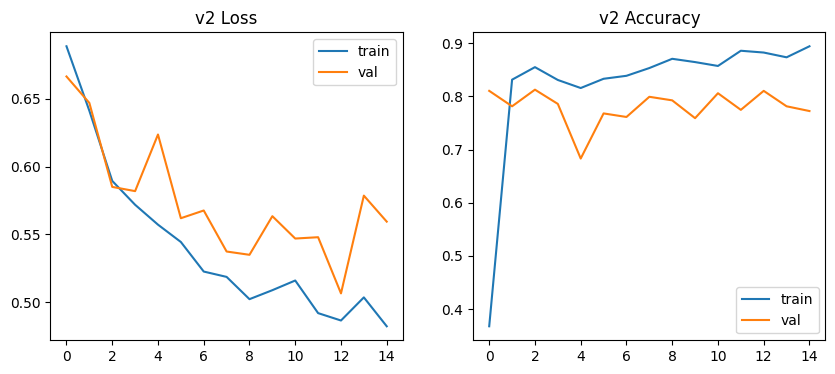

In [24]:
# ---- Q7 评估：v1 与 v2 在同一验证集上对垒 + v1 在新负样本上的翻车现场 ----
def eval_on(model_, ds, prep=None):                  # 通用评估
    ys, ps = [], []                                  # 收集
    for X, Y in ds:                                  # 遍历
        Xin = prep(X) if prep else X                 # 可选的输入适配
        ps.append(model_.predict(Xin, verbose=0)[:, 0])          # 预测
        ys.append(Y.numpy())                         # 真值
    ys = np.concatenate(ys); ps = np.concatenate(ps) # 拼接
    pred = (ps > 0.5).astype(int)                    # 二值化
    tp = int(((pred == 1) & (ys == 1)).sum()); fp = int(((pred == 1) & (ys == 0)).sum())         # 混淆项
    fn = int(((pred == 0) & (ys == 1)).sum()); tn = int(((pred == 0) & (ys == 0)).sum())         # 混淆项
    return dict(acc=(pred == ys).mean(), prec=tp / max(1, tp + fp), rec=tp / max(1, tp + fn),    # 三个指标
                tp=tp, fp=fp, fn=fn, tn=tn)          # 混淆计数

m2 = eval_on(model2, val_ds2)                        # v2 在 v2 验证集
print(f"v2 on new val: acc={m2['acc']:.1%} precision={m2['prec']:.1%} recall={m2['rec']:.1%} "   # 汇报
      f"(tp={m2['tp']} fp={m2['fp']} fn={m2['fn']} tn={m2['tn']})")              # 混淆

# v1 在新的多样化负样本上会怎样？（v1 吃 128×128 的前 3 通道=B1,B2,B3；新负样本前 3 波段正好也是 B1,B2,B3，可公平投喂）
def v1_on_negs():                                    # 专测 200 个新负样本
    from skimage.transform import resize             # 缩放
    fps = 0; n = 0                                   # 假阳计数
    for f in sorted(glob.glob('patch_store/neg_batch_*.npz')):   # 逐负样本批
        X = np.load(f)['X'][..., :3]                 # 前 3 通道 = B1,B2,B3（与 v1 训练时一致）
        Xr = np.stack([resize(x, (128, 128, 3), anti_aliasing=True) for x in X]).astype(np.float32)          # 缩放到 v1 输入
        p = model.predict(Xr, verbose=0)[:, 0]       # v1 预测
        fps += int((p > 0.5).sum()); n += len(p)     # 判成"有光伏"的数量
    return fps, n                                    # 返回

fp1, nn = v1_on_negs()                               # 跑
print(f'v1 on 200 diverse negatives: {fp1}/{nn} classified as solar ({fp1/nn:.1%} false alarms)')            # v1 翻车率

plt.figure(figsize=(10, 4))                          # v2 训练曲线
plt.subplot(1, 2, 1)                                 # 左：损失
plt.plot(history2.history['loss'], label='train'); plt.plot(history2.history['val_loss'], label='val')       # 曲线
plt.title('v2 Loss'); plt.legend()                   # 标题图例
plt.subplot(1, 2, 2)                                 # 右：准确率
plt.plot(history2.history['accuracy'], label='train'); plt.plot(history2.history['val_accuracy'], label='val')           # 曲线
plt.title('v2 Accuracy'); plt.legend()               # 标题图例
plt.savefig('lab4_figs/fig_q7_curves.png', dpi=110, bbox_inches='tight')         # 存盘
plt.show()                                           # 显示

__ANSWER7_PLACEHOLDER__